In [34]:
import pandas as pd
import matplotlib.pyplot as plt

In [35]:
pred_data = pd.read_csv("backtest_result.csv")
data = pd.read_csv("data.csv")

In [36]:
pred_data.head()

,date,actual,prophet_pred
0,2026-06-11,196.0,221.49
1,2026-06-12,90.0,210.03
2,2026-06-13,254.4,231.84
3,2026-06-14,214.8,267.95
4,2026-06-15,174.0,205.47


In [37]:
data.head()

,date,volume_litres,region,product_type
0,2024-11-04,71.0,West,Small
1,2024-11-05,185.0,West,Medium
2,2024-11-06,117.0,Nort,Small
3,2024-11-07,317.0,Nort,Large
4,2024-11-08,107.0,West,Small


In [38]:
merged = pred_data.merge(data[["date", "region", "product_type"]], on = "date")
print("Rows:" , len(merged))

Rows: 146


In [39]:
merged["error"] = merged.actual - merged.prophet_pred
merged["abs_error"] = merged.error.abs()
merged["pct_error"] = (merged.abs_error / merged.actual) * 100

In [40]:
by_region = merged.groupby("region")[["abs_error", "pct_error"]].mean().round(2)
by_region.columns = ["MAE", "MAPE"]
by_region = by_region.reset_index()
by_region.to_csv("error_by_region.csv", index= False)

In [41]:
by_product = merged.groupby("product_type")[["abs_error", "pct_error"]].mean().round(2)
by_product.columns = ["MAE", "MAPE"]
by_product = by_product.reset_index()
by_product.to_csv("error_by_product.csv", index = False)

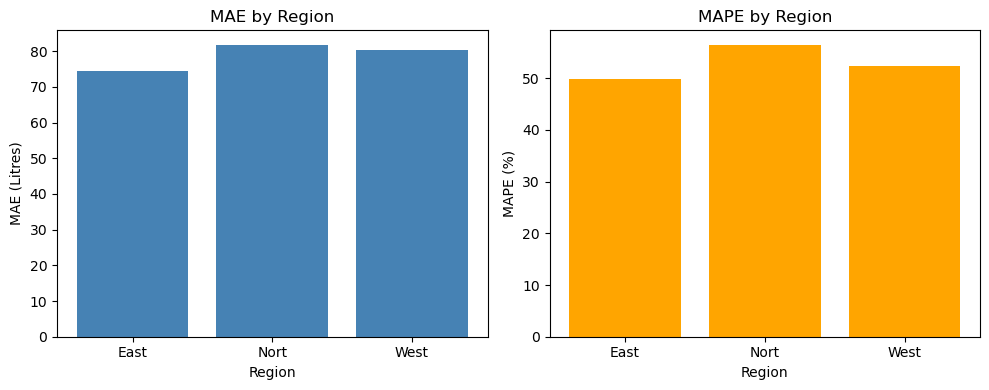

In [42]:
fig, axes = plt.subplots(1,2, figsize =(10,4))
axes[0].bar(by_region["region"], by_region["MAE"], color = "steelblue")
axes[0].set_title("MAE by Region")
axes[0].set_xlabel("Region")
axes[0].set_ylabel("MAE (Litres)")
axes[1].bar(by_region["region"], by_region["MAPE"], color= "orange")
axes[1].set_title("MAPE by Region")
axes[1].set_xlabel("Region")
axes[1].set_ylabel("MAPE (%)")
plt.tight_layout()
plt.savefig("region_error.png")
plt.show()

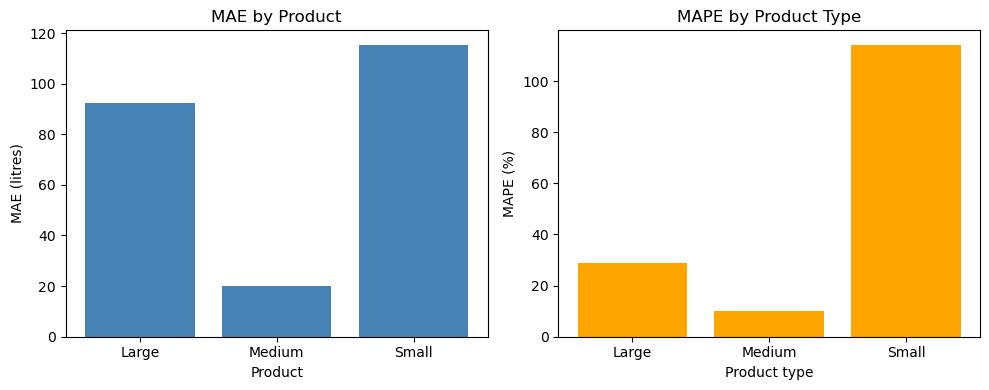

In [43]:
fig , axes = plt.subplots(1,2 , figsize = (10,4))
axes[0].bar(by_product["product_type"], by_product["MAE"], color = "steelblue")
axes[0].set_title("MAE by Product")
axes[0].set_xlabel("Product")
axes[0].set_ylabel("MAE (litres)")

axes[1].bar(by_product["product_type"], by_product["MAPE"], color="orange")
axes[1].set_title("MAPE by Product Type")
axes[1].set_xlabel("Product type")
axes[1].set_ylabel("MAPE (%)")
plt.tight_layout()
plt.savefig("product_error.png")
plt.show()

In [44]:
print(by_region)

  region    MAE   MAPE
0   East  74.36  49.92
1   Nort  81.73  56.46
2   West  80.28  52.33


In [45]:
print(by_product)

  product_type     MAE    MAPE
0        Large   92.24   29.04
1       Medium   20.16   10.04
2        Small  115.31  114.17
